In [9]:
import sys,os
sys.path.append('../../')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from utils import makefolder

# Style
rcpsize = 14
plt.rcParams['xtick.labelsize'] = rcpsize
plt.rcParams['ytick.labelsize'] = rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
base_colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
plt.rcParams['axes.prop_cycle'] = cycler(color=base_colors)

# Shared config
base_results = './results/santiago/'
model = 'deepseek'
n_files = 400
min_token_length = 40
mask = 2
n_loaded_tokens = min_token_length - mask
k = 10
Nbits = 0
n_tokens = 1
seed_list = np.arange(5, dtype=int)
take_last = 1
batch_shuffle = 0
subtract_mean = 0
figs_dir = Path('results/figs')
figs_dir.mkdir(parents=True, exist_ok=True)

def seed_folder(language: str, seed: int) -> str:
    return makefolder(
        base=base_results,
        subtract_mean=subtract_mean,
        batch_shuffle=batch_shuffle,
        take_last=take_last,
        modelA=model,
        modelB=model,
        n_files=n_files,
        min_token_length=min_token_length,
        languageA=language,
        mask=mask,
        k=k,
        Nbits=Nbits,
        seed=seed,
    )

def load_iis(language: str):
    ab_list, ba_list = [], []
    for seed in seed_list:
        folder = seed_folder(language, seed)
        ab_list.append(np.load(folder + f'n_tokens_{n_tokens}_avg_0_AB.npy'))
        ba_list.append(np.load(folder + f'n_tokens_{n_tokens}_avg_0_BA.npy'))
    ab = np.stack(ab_list, axis=0)
    ba = np.stack(ba_list, axis=0)
    return ab, ba

# Infer depth from data
_ab_en, _ = load_iis('english')
model_depth = _ab_en.shape[1]
print(f'model_depth={model_depth}, n_loaded_tokens={n_loaded_tokens}')


model_depth=61, n_loaded_tokens=38


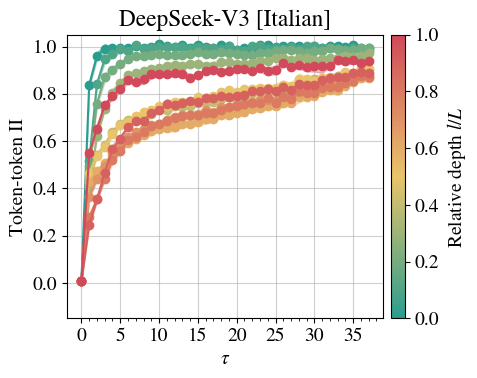

In [10]:
# Plot 1: continuous-depth token-token II (Italian)
language = 'italian'
ab, _ = load_iis(language)

relative_depths = np.array([0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])
layer_ids = np.clip((relative_depths * model_depth).astype(int), 0, model_depth - 1)

depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'depth3', ['#2A9D8F', '#E9C46A', '#D1495B'], N=256
)
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
depth_colors = depth_cmap(depth_norm(relative_depths))

x = np.arange(n_loaded_tokens)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
for i, layer_id in enumerate(layer_ids):
    mu = ab[:, layer_id, :].mean(axis=0)
    std = ab[:, layer_id, :].std(axis=0)
    ax.plot(x, mu, linestyle='-', marker='o', color=depth_colors[i])
    ax.fill_between(x, mu - std, mu + std, alpha=0.35, color=depth_colors[i])

ax.set_xlabel(r'$\tau$')
ax.set_ylabel('Token-token II')
ax.set_xticks(np.arange(0, n_loaded_tokens + 1, 5))
ax.set_xticks(np.arange(0, n_loaded_tokens + 1, 1), minor=True)
ax.grid(which='major', alpha=0.6)
ax.set_ylim(-0.15, 1.05)
ax.set_title('DeepSeek-V3 [Italian]')

sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

plt.show()


/tmp/ipykernel_2485749/2580454070.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.savefig(figs_dir / '_deepseek_english_vs_italian_correlations.pdf', bbox_inches='tight')
/home/acevedo/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


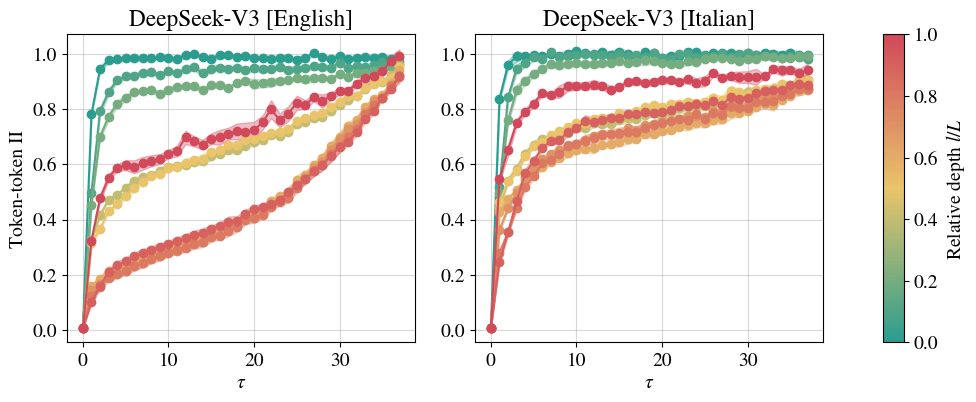

In [11]:
# Plot 2: side-by-side token-token II (English vs Italian)
compare_languages = ['english', 'italian']
relative_depths = np.array([0.001, 0.1, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.999])
layer_ids = np.clip((relative_depths * model_depth).astype(int), 0, model_depth - 1)

depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'depth3_compare', ['#2A9D8F', '#E9C46A', '#D1495B'], N=256
)
depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
depth_colors = depth_cmap(depth_norm(relative_depths))

fig = plt.figure(figsize=(10.8, 4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.06], wspace=0.25)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1], sharey=ax0)
cax = fig.add_subplot(gs[0, 2])
axes = [ax0, ax1]

x = np.arange(n_loaded_tokens)
for ax, language in zip(axes, compare_languages):
    ab, _ = load_iis(language)
    for i, layer_id in enumerate(layer_ids):
        mu = ab[:, layer_id, :].mean(axis=0)
        std = ab[:, layer_id, :].std(axis=0)
        ax.plot(x, mu, linestyle='-', marker='o', color=depth_colors[i])
        ax.fill_between(x, mu - std, mu + std, alpha=0.35, color=depth_colors[i])

    ax.grid(alpha=0.5)
    ax.set_xlabel(r'$\tau$')
    ax.set_title(f'DeepSeek-V3 [{language.title()}]')

ax0.set_ylabel('Token-token II')
sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'Relative depth $l/L$')
ticks = np.round(np.linspace(0.0, 1.0, 6), 2)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t:.1f}' for t in ticks])

fig.savefig(figs_dir / '_deepseek_english_vs_italian_correlations.pdf', bbox_inches='tight')
plt.show()


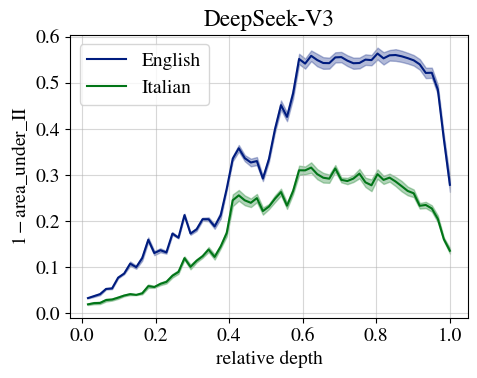

In [12]:
# Plot 3: 1 - area_under_II vs relative depth (English vs Italian)
compare_languages = ['english', 'italian']
x_tau = np.arange(n_loaded_tokens)
relative_depths = np.arange(1, model_depth + 1) / model_depth

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
for language_id, language in enumerate(compare_languages):
    ab, _ = load_iis(language)
    area_under_ii = np.trapezoid(ab, x=x_tau, axis=-1) / (n_loaded_tokens - 1)
    one_minus_area = 1.0 - area_under_ii

    mu = one_minus_area.mean(axis=0)
    std = one_minus_area.std(axis=0)
    color = base_colors[language_id % len(base_colors)]
    ax.plot(relative_depths, mu, color=color, label=language.title())
    ax.fill_between(relative_depths, mu - std, mu + std, color=color, alpha=0.30)

ax.set_xlabel('relative depth')
ax.set_ylabel(r'$1-\mathrm{area\_under\_II}$')
ax.set_title('DeepSeek-V3')
ax.grid(alpha=0.5)
ax.legend()

plt.show()
